# Phase 6 · Q·K·V & 셀프 어텐션 — 점수를 스스로 계산 🔑

웹 챕터 **"Q·K·V"** 와 짝을 이루는 실습입니다. 트랜스포머의 **가장 핵심**이에요.
웹에서 Query 를 슬라이더로 움직였다면, 여기서는 **Q·K·V 전체 어텐션**을 행렬로 직접 계산합니다.

준비물: `pip install -r requirements.txt`

> 🤖 **AI 튜터** — 아래 셀을 실행하면 웹앱처럼 화면 오른쪽 아래에 🤖 버튼이 생깁니다.
> 버튼을 누르면 채팅창이 열리고, 어디를 스크롤해도 그 자리에 떠 있어요. 막히면 언제든 질문하세요.
> (로컬 Ollama 필요 — 꺼져 있으면 켜는 방법이 안내되고, 튜터 없이도 학습에는 지장 없습니다.)

In [ ]:
# 🤖 AI 튜터 — 실행하면 오른쪽 아래에 🤖 버튼이 떠요
from tutor import chat

chat('ch6')

## 1. 각 단어의 Key·Value, 그리고 Query

"강아지 · 공 · 물었다" 세 단어. 각 단어의 Key(열쇠)·Value(값) 벡터입니다. (웹 실험실과 같은 값)

In [1]:
import numpy as np

WORDS = ['강아지', '공', '물었다']
KEY = np.array([[1.4, 0.3], [0.3, 1.4], [0.4, 0.4]])   # 열쇠(매칭용)
VAL = np.array([[1.0, 0.0], [0.0, 1.0], [0.5, 0.5]])   # 값(전달용)
QDEF = np.array([[1.4, 0.2], [0.2, 1.4], [1.0, 1.0]])  # 단어별 기본 Query

def softmax(z):
    z = np.asarray(z, float); z = z - z.max()
    e = np.exp(z); return e / e.sum()

## 2. 점수 = Query · Key (내적)

'물었다'의 Query 로 각 단어의 Key 와 **내적**해 점수를 냅니다.
$$Q\cdot K = q_1k_1 + q_2k_2$$

In [2]:
q = QDEF[2]                 # '물었다'의 질문
scores = KEY @ q           # 각 Key 와의 내적
for w, s in zip(WORDS, scores):
    print(f'{w}: 점수 {s:.2f}')

weights = softmax(scores)
print('집중도:', np.round(weights, 3), ' 합=', round(weights.sum(), 3))
out = weights @ VAL         # Value 가중합
print('출력(새 문맥 벡터):', np.round(out, 2))

강아지: 점수 1.70
공: 점수 1.70
물었다: 점수 0.80
집중도: [0.416 0.416 0.169]  합= 1.0
출력(새 문맥 벡터): [0.5 0.5]


## 3. 전체 셀프 어텐션 (스케일드 닷프로덕트)

모든 단어가 자기 Query 로 모두의 Key 를 비교 → 소프트맥스 → Value 가중합.
$$\text{Attention}(Q,K,V) = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d}}\right)V$$

In [3]:
def attention(Q, K, V):
    d = Q.shape[-1]
    scores = Q @ K.T / np.sqrt(d)          # 스케일링된 점수 표
    weights = np.apply_along_axis(softmax, 1, scores)
    return weights @ V, weights

out, attn = attention(QDEF, KEY, VAL)
print('어텐션 집중도 행렬 (행=질문 단어):')
print('           ' + '  '.join(f'{w:>5}' for w in WORDS))
for i, w in enumerate(WORDS):
    print(f'{w:>7} :  ' + '  '.join(f'{p:5.2f}' for p in attn[i]))
print('\n각 단어의 새 문맥 벡터(출력):')
print(np.round(out, 2))

어텐션 집중도 행렬 (행=질문 단어):
             강아지      공    물었다
    강아지 :   0.56   0.22   0.21
      공 :   0.22   0.56   0.21
    물었다 :   0.40   0.40   0.21

각 단어의 새 문맥 벡터(출력):
[[0.67 0.33]
 [0.33 0.67]
 [0.5  0.5 ]]


## 4. 히트맵으로 보기

밝을수록 강하게 참고. '물었다'가 강아지·공(주어·목적어)을 함께 보는 게 보이나요?

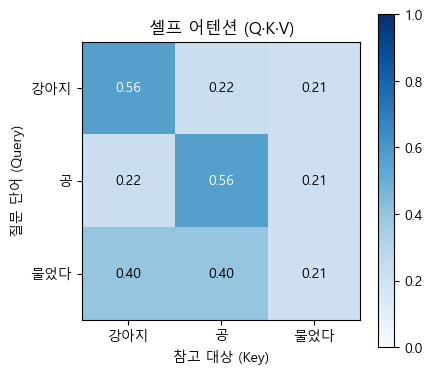

In [4]:
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

plt.figure(figsize=(4.5, 4))
plt.imshow(attn, cmap='Blues', vmin=0, vmax=1)
plt.xticks(range(3), WORDS); plt.yticks(range(3), WORDS)
plt.xlabel('참고 대상 (Key)'); plt.ylabel('질문 단어 (Query)')
for i in range(3):
    for j in range(3):
        plt.text(j, i, f'{attn[i,j]:.2f}', ha='center', va='center',
                 color='white' if attn[i,j] > 0.5 else 'black')
plt.title('셀프 어텐션 (Q·K·V)'); plt.colorbar(); plt.tight_layout(); plt.show()

## 5. 직접 해보기 ✏️

Query `(1, 2)` 와 Key `(3, 1)` 의 내적(점수)을 구하세요. (웹 StepQuiz 와 같은 문제)

In [5]:
Q = np.array([1, 2]); K = np.array([3, 1])
score = Q @ K
print('내적(점수):', score)

assert score == 5, '성분끼리 곱해서 더하세요: 1*3 + 2*1'
print('✅ 1·3 + 2·1 = 5')

내적(점수): 5
✅ 1·3 + 2·1 = 5


---
이걸로 트랜스포머의 **심장(Q·K·V 셀프 어텐션)** 을 통과했습니다! 🎉
다음 챕터(ch7)에서는 이 어텐션을 **여러 개 동시에** 돌리는 **멀티헤드 어텐션**을 배웁니다. 🧠🧠🧠